# EDA et résultats — Maintenance prédictive C-MAPSS FD001

Ce notebook regroupe les figures principales à générer pour le rapport.

**EDA :** capteurs constants, durée de vie, trajectoires, corrélations et distribution de la RUL.

**Résultats :** comparaison MAE/RMSE, PHM08 × 100, GroupKFold, prédictions/résidus LSTM et importance LightGBM si les fichiers correspondants sont présents.


In [21]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 120,
})

#notebook

from pathlib import Path

DATA_DIRS = [
    # "../data/processed",
    # "data/interim",
    "../data/raw",
]

RESULT_DIRS = [
    "../results",
]

FIG_DIR = "reports/figures"
def find_csv(names):
    for d in DATA_DIRS + RESULT_DIRS:
        for name in names:
            p = Path(d) / name
            print(p)
            if p.exists():
                print(f"Found {name} in {d}")
                return p
    return None

def load_csv(names):
    p = find_csv(names)
    return (pd.read_csv(p), p) if p else (None, None)

train_df, train_path = load_csv(["train_data.csv"])
print("Train :", train_path)
if train_df is not None:
    print("Shape :", train_df.shape)
else:
    print("CSV train introuvable : adaptez DATA_DIRS si nécessaire.")


../data/raw/train_data.csv
Found train_data.csv in ../data/raw
Train : ../data/raw/train_data.csv
Shape : (20631, 26)


## 1. Capteurs constants / quasi-constants

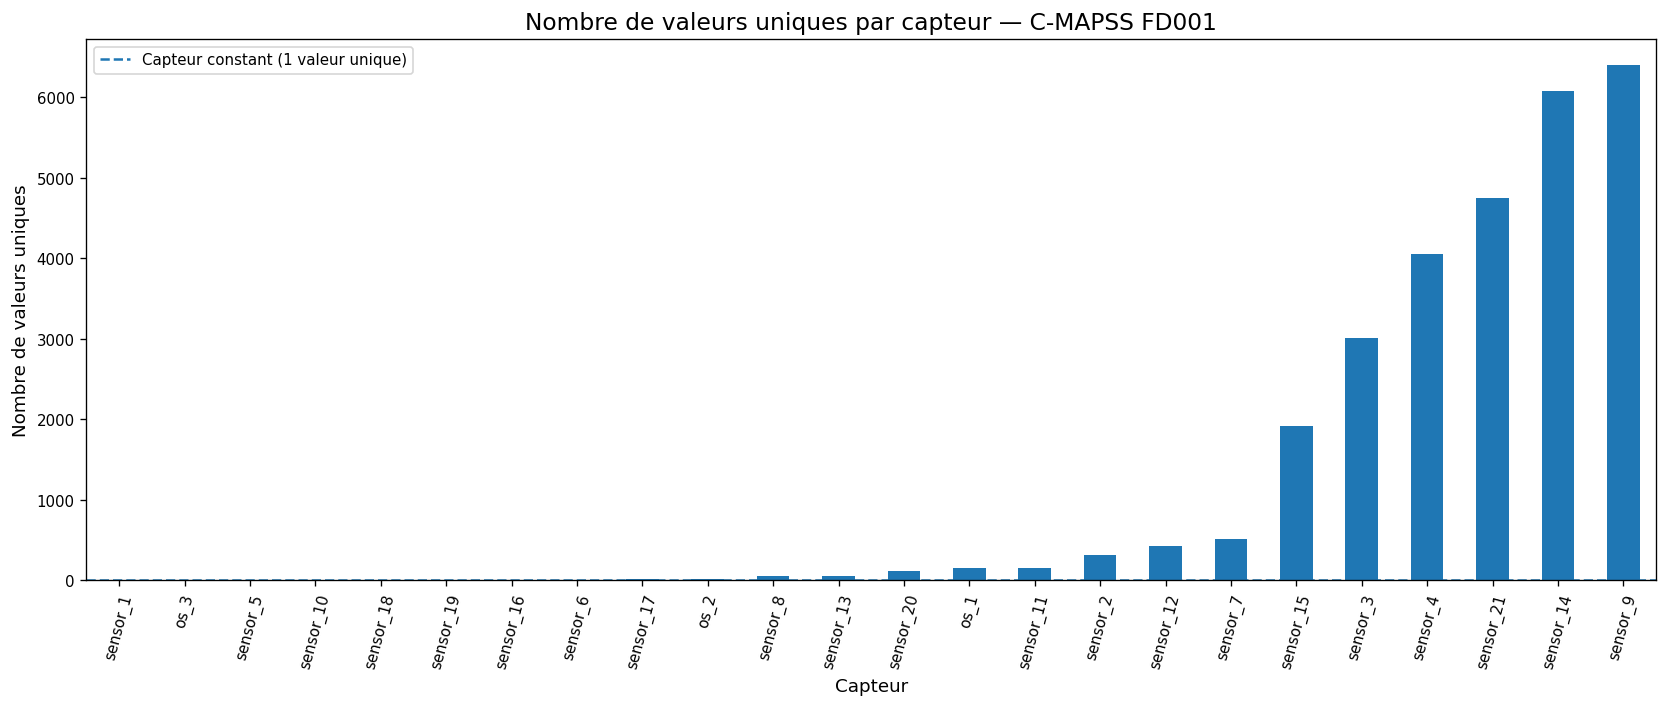

In [23]:
if train_df is not None:
    cols = [
        c for c in train_df.select_dtypes("number").columns
        if c not in {"unit", "cycle", "RUL"}
    ]

    n_unique = train_df[cols].nunique().sort_values()

    plt.figure(figsize=(14, 6))
    n_unique.plot(kind="bar")

    plt.axhline(1, linestyle="--", linewidth=1.5,
                label="Capteur constant (1 valeur unique)")

    plt.title("Nombre de valeurs uniques par capteur — C-MAPSS FD001")
    plt.xlabel("Capteur")
    plt.ylabel("Nombre de valeurs uniques")
    plt.xticks(rotation=75)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Distribution de la durée de vie des moteurs

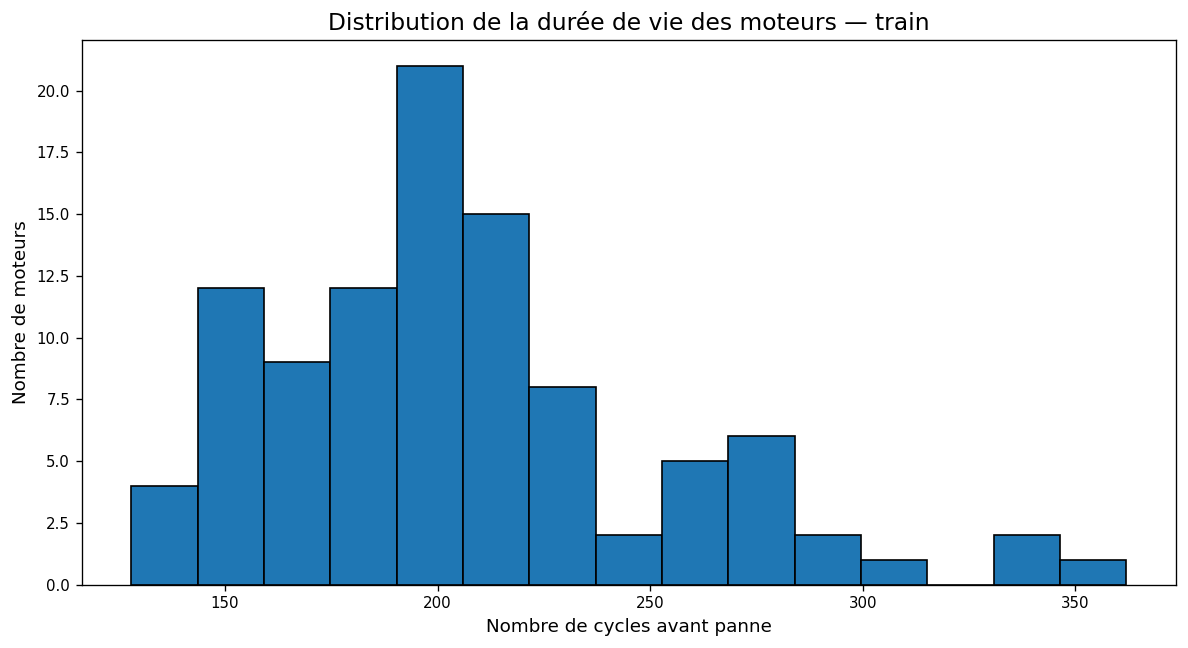

In [25]:
if train_df is not None and {"unit","cycle"}.issubset(train_df.columns):
    life = train_df.groupby("unit")["cycle"].max()
    plt.figure()
    plt.hist(life, bins=15, edgecolor="black")
    plt.title("Distribution de la durée de vie des moteurs — train")
    plt.xlabel("Nombre de cycles avant panne")
    plt.ylabel("Nombre de moteurs")
    plt.tight_layout()
    plt.show()


## 3. Trajectoires de dégradation

Quatre capteurs représentatifs sont tracés pour cinq moteurs. Les capteurs disponibles sont sélectionnés automatiquement.


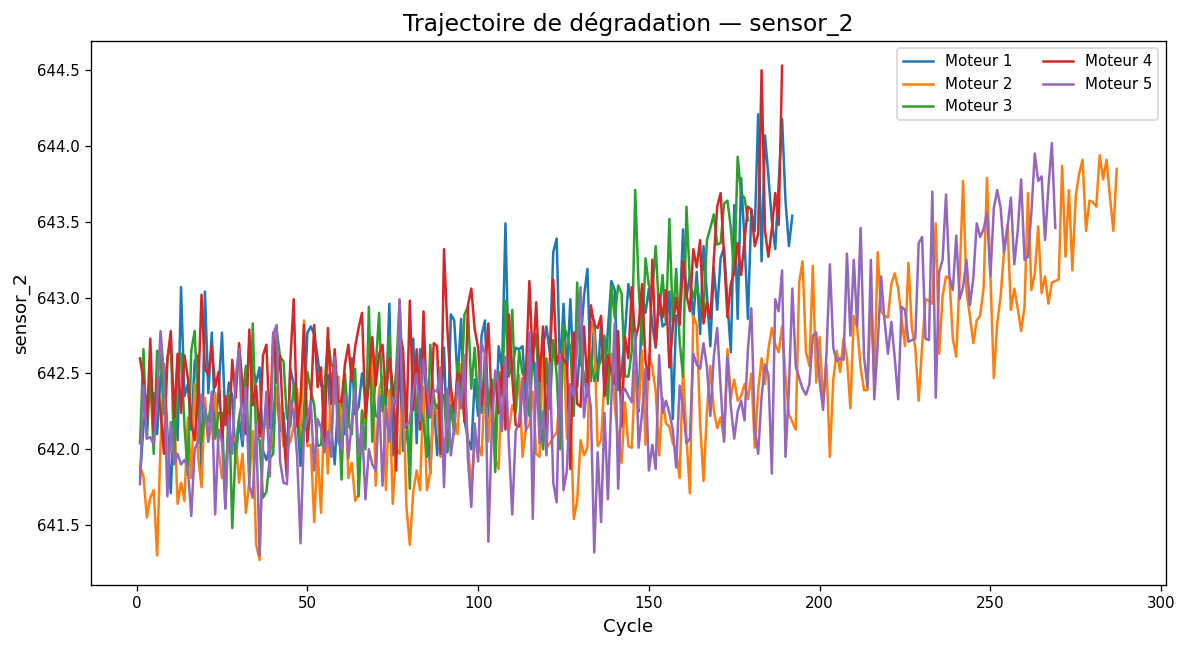

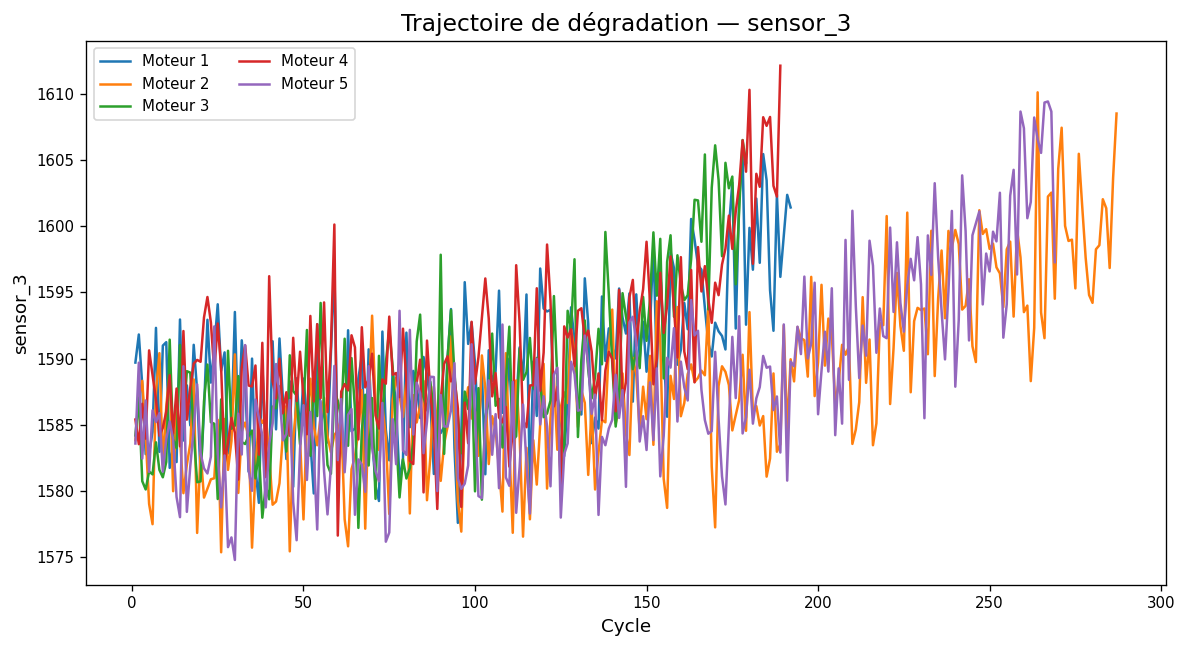

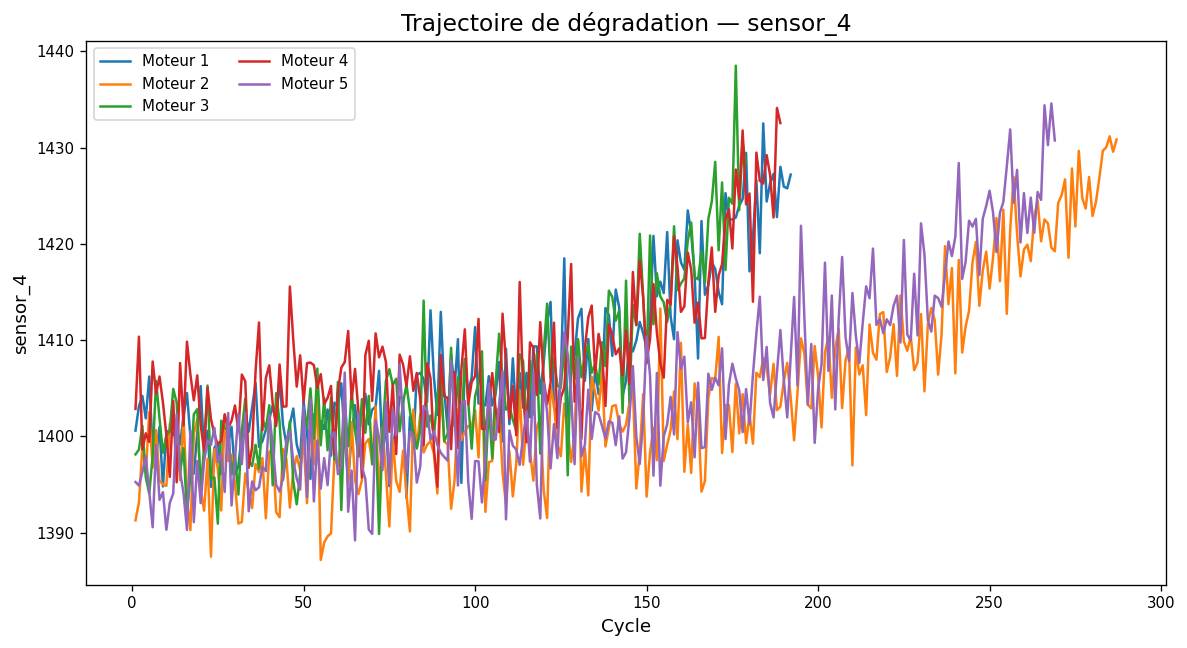

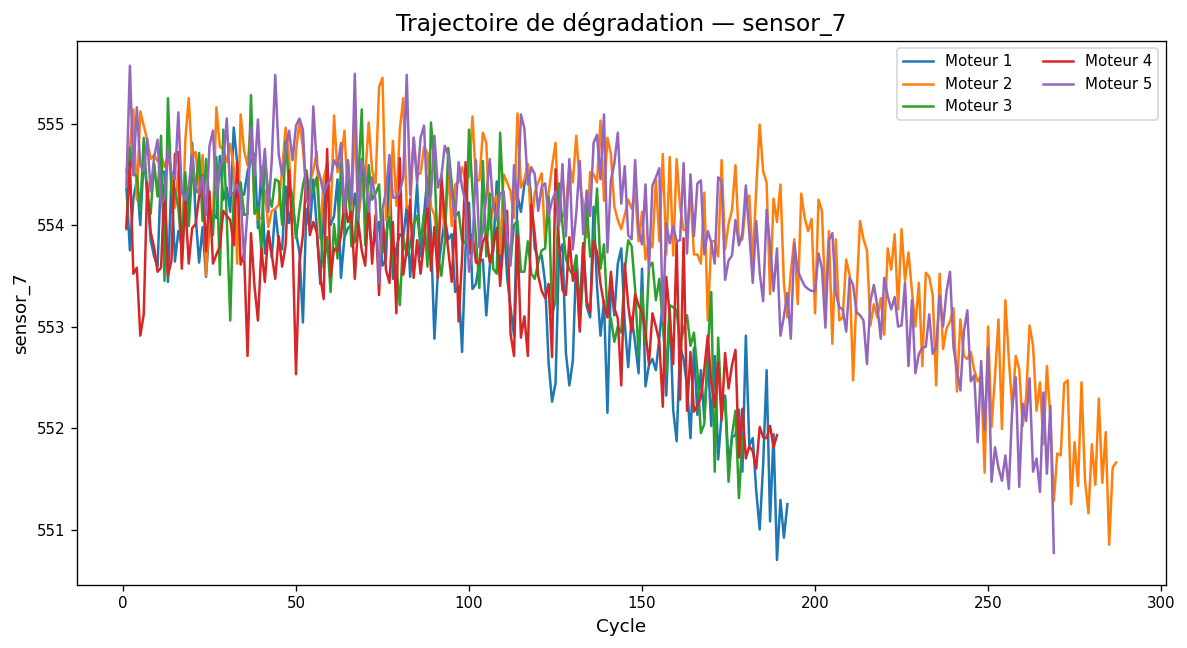

In [26]:
if train_df is not None and {"unit","cycle"}.issubset(train_df.columns):
    candidates = ["sensor_2","sensor_3","sensor_4","sensor_7",
                  "sensor_8","sensor_11","sensor_12","sensor_15",
                  "sensor_17","sensor_20","sensor_21"]
    sensors = [c for c in candidates if c in train_df.columns][:4]
    units = sorted(train_df["unit"].unique())[:5]

    for sensor in sensors:
        plt.figure()
        for unit in units:
            g = train_df[train_df.unit == unit].sort_values("cycle")
            plt.plot(g.cycle, g[sensor], label=f"Moteur {int(unit)}")
        plt.title(f"Trajectoire de dégradation — {sensor}")
        plt.xlabel("Cycle")
        plt.ylabel(sensor)
        plt.legend(ncol=2)
        plt.tight_layout()
        plt.show()


## 4. Matrice de corrélation des capteurs non constants

TypeError: unsupported operand type(s) for /: 'str' and 'str'

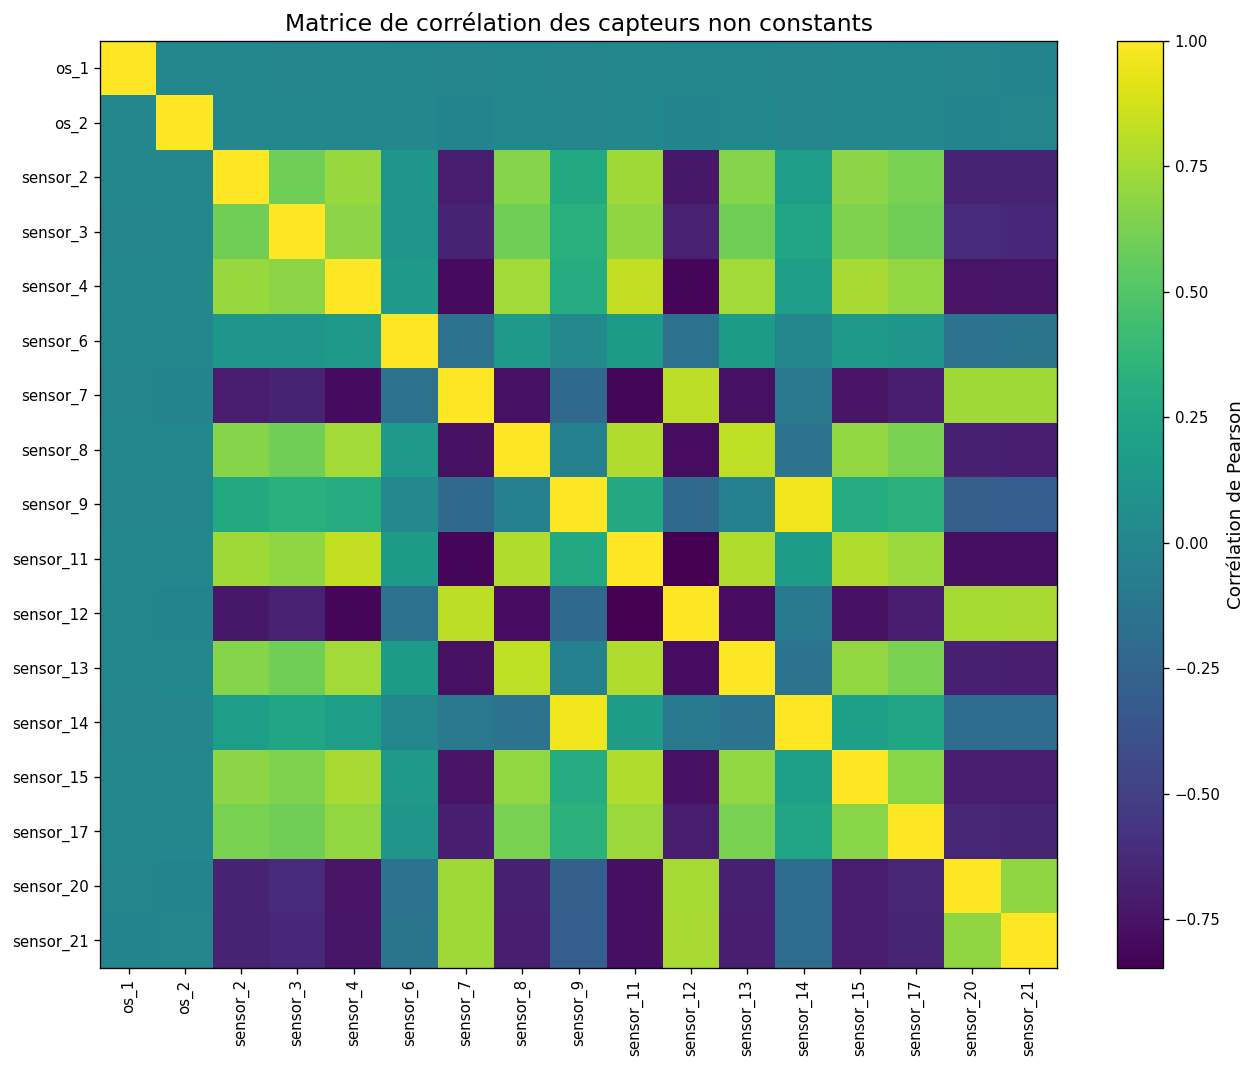

In [27]:
if train_df is not None:
    cols = [c for c in train_df.select_dtypes("number").columns
            if c not in {"unit","cycle","RUL"}]
    cols = [c for c in cols if train_df[c].std() > 1e-12]
    corr = train_df[cols].corr()

    plt.figure(figsize=(11,9))
    plt.imshow(corr, aspect="auto", interpolation="nearest")
    plt.colorbar(label="Corrélation de Pearson")
    plt.xticks(range(len(cols)), cols, rotation=90)
    plt.yticks(range(len(cols)), cols)
    plt.title("Matrice de corrélation des capteurs non constants")
    plt.tight_layout()
    plt.savefig(FIG_DIR/"eda_correlation_capteurs.png", bbox_inches="tight")
    plt.show()


## 5. Distribution de la RUL

In [ ]:
if train_df is not None and "RUL" in train_df.columns:
    plt.figure()
    plt.hist(train_df.RUL.dropna(), bins=30, edgecolor="black")
    plt.title("Distribution de la RUL — jeu d'entraînement")
    plt.xlabel("RUL (cycles)")
    plt.ylabel("Nombre d'observations")
    plt.tight_layout()
    plt.savefig(FIG_DIR/"eda_distribution_rul.png", bbox_inches="tight")
    plt.show()


# Résultats finaux

Résultats officiels sur les **100 moteurs du jeu de test**. Le PHM08 est présenté après multiplication par 100.


In [28]:
final_results = pd.DataFrame({
    "Modèle": ["LSTM","LightGBM","XGBoost","Régression linéaire"],
    "MAE": [9.55,11.92,12.43,16.02],
    "RMSE": [13.23,16.62,16.93,20.25],
    "PHM08 × 100": [330.23,637.70,621.14,1046.03],
    "Moteurs": [100,100,100,100],
})
final_results


,Modèle,MAE,RMSE,PHM08 × 100,Moteurs
0,LSTM,9.55,13.23,330.23,100
1,LightGBM,11.92,16.62,637.70,100
2,XGBoost,12.43,16.93,621.14,100
3,Régression linéaire,16.02,20.25,1046.03,100


## 6. Comparaison MAE / RMSE

TypeError: unsupported operand type(s) for /: 'str' and 'str'

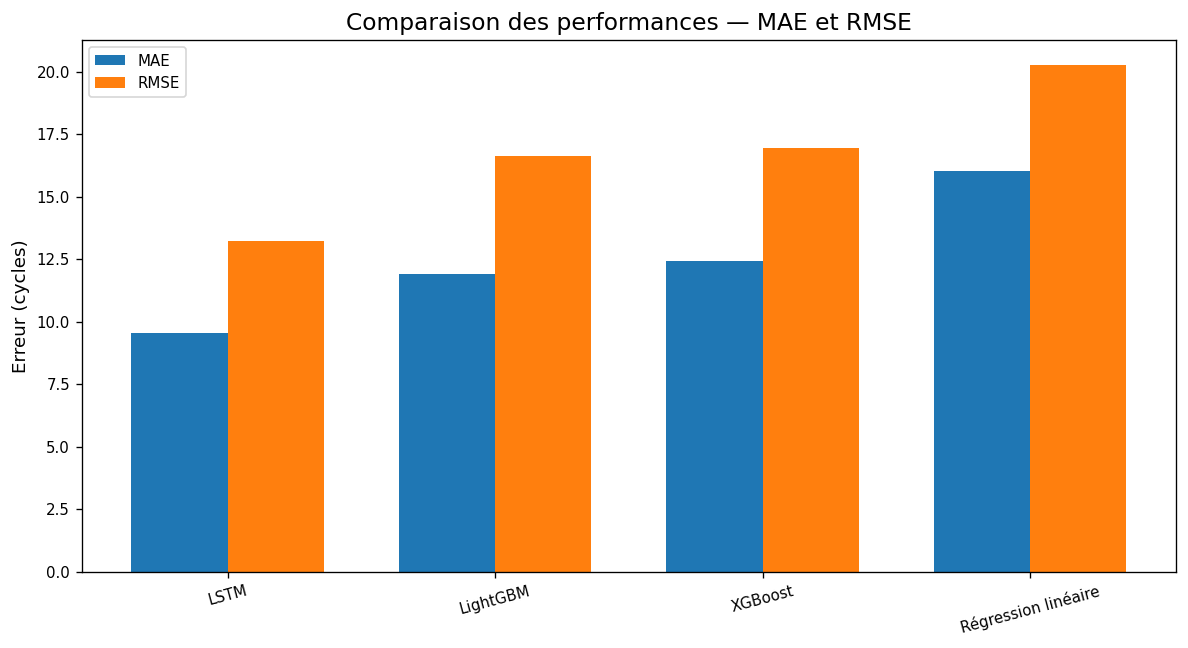

In [29]:
x = np.arange(len(final_results))
w = 0.36
plt.figure()
plt.bar(x-w/2, final_results.MAE, w, label="MAE")
plt.bar(x+w/2, final_results.RMSE, w, label="RMSE")
plt.xticks(x, final_results.Modèle, rotation=15)
plt.ylabel("Erreur (cycles)")
plt.title("Comparaison des performances — MAE et RMSE")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR/"resultats_mae_rmse.png", bbox_inches="tight")
plt.show()


## 7. Comparaison du score PHM08

TypeError: unsupported operand type(s) for /: 'str' and 'str'

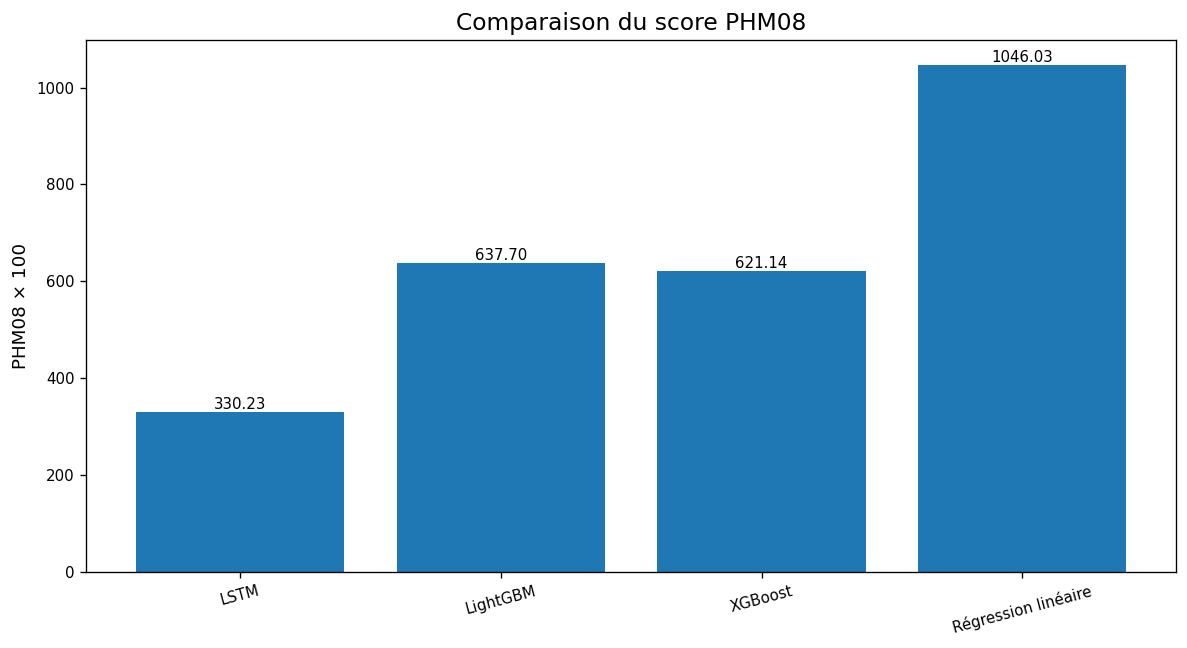

In [30]:
plt.figure()
bars = plt.bar(final_results.Modèle, final_results["PHM08 × 100"])
plt.ylabel("PHM08 × 100")
plt.title("Comparaison du score PHM08")
plt.xticks(rotation=15)
for b, v in zip(bars, final_results["PHM08 × 100"]):
    plt.text(b.get_x()+b.get_width()/2, b.get_height(), f"{v:.2f}",
             ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR/"resultats_phm08.png", bbox_inches="tight")
plt.show()


## 8. GroupKFold — modèles tabulaires

Validation avec `GroupKFold(n_splits=5)` et `unit` comme groupe.


In [31]:
gkf_results = pd.DataFrame({
    "Modèle": ["LightGBM","XGBoost","Régression linéaire"],
    "MAE": [12.889455,13.022532,16.967198],
    "RMSE": [17.793447,17.926100,20.920921],
    "PHM08 × 100": [1063.78,1091.75,1053.38],
})
gkf_results.round(2)


,Modèle,MAE,RMSE,PHM08 × 100
0,LightGBM,12.89,17.79,1063.78
1,XGBoost,13.02,17.93,1091.75
2,Régression linéaire,16.97,20.92,1053.38


TypeError: unsupported operand type(s) for /: 'str' and 'str'

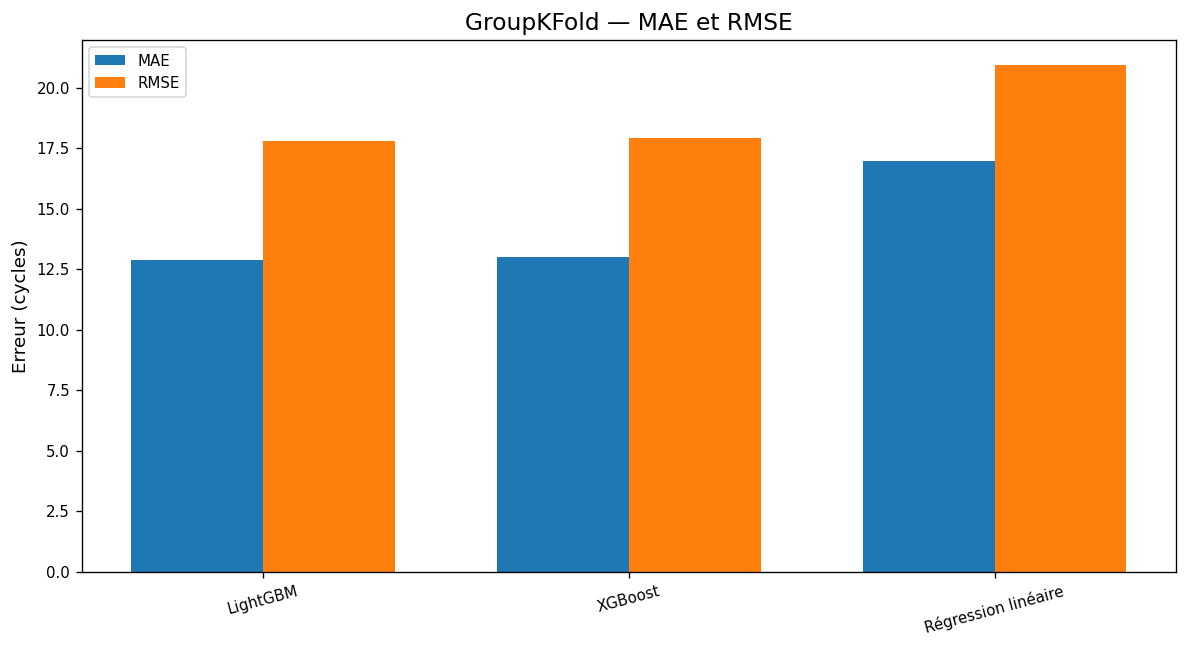

In [32]:
x = np.arange(len(gkf_results))
w = 0.36
plt.figure()
plt.bar(x-w/2, gkf_results.MAE, w, label="MAE")
plt.bar(x+w/2, gkf_results.RMSE, w, label="RMSE")
plt.xticks(x, gkf_results.Modèle, rotation=15)
plt.ylabel("Erreur (cycles)")
plt.title("GroupKFold — MAE et RMSE")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR/"groupkfold_mae_rmse.png", bbox_inches="tight")
plt.show()


## 9. LSTM — RUL réelle vs RUL prédite

Cette figure est produite si `lstm_predictions.csv`, `predictions.csv` ou `test_predictions.csv` existe.


../data/raw/lstm_predictions.csv
../data/raw/predictions.csv
../data/raw/test_predictions.csv
../results/lstm_predictions.csv
../results/predictions.csv
Found predictions.csv in ../results
Prédictions : ../results/predictions.csv


TypeError: unsupported operand type(s) for /: 'str' and 'str'

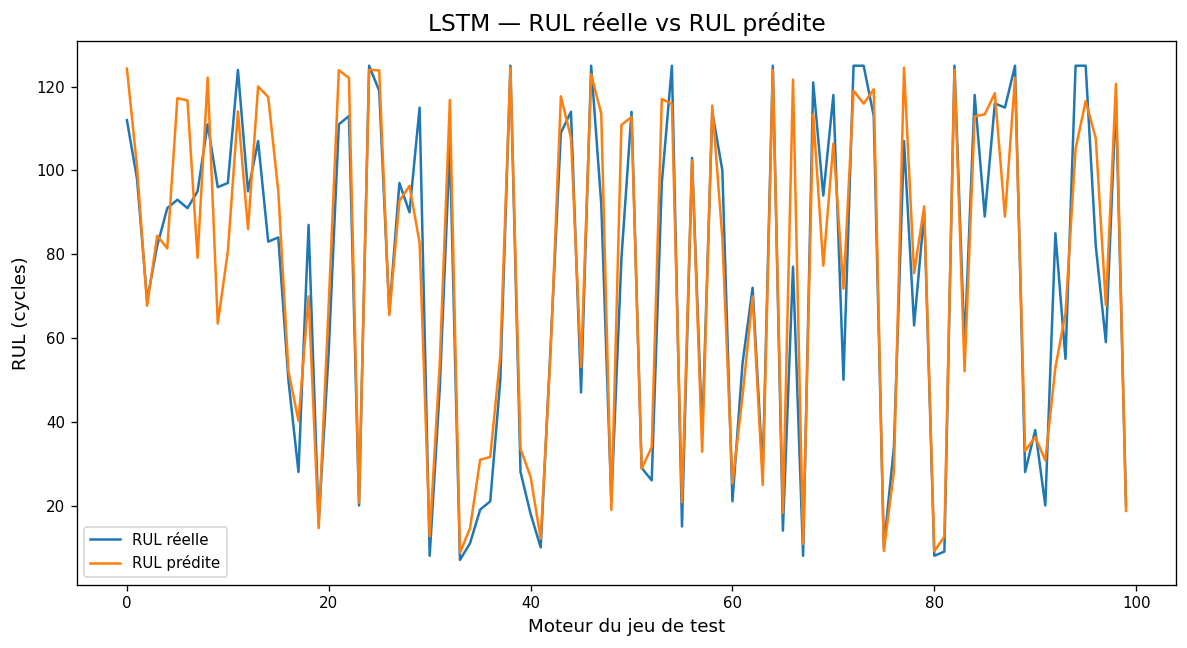

In [34]:
prediction_df, prediction_path = load_csv(
    ["lstm_predictions.csv","predictions.csv","test_predictions.csv"]
)
print("Prédictions :", prediction_path)

if prediction_df is not None:
    true_col = next((c for c in ["y_true","true","RUL_true","RUL","actual"]
                     if c in prediction_df.columns), None)
    pred_col = next((c for c in ["y_pred","pred","RUL_pred","prediction","predicted"]
                     if c in prediction_df.columns), None)

    if true_col and pred_col:
        p = prediction_df[[true_col,pred_col]].dropna()
        plt.figure()
        plt.plot(p[true_col].values, label="RUL réelle")
        plt.plot(p[pred_col].values, label="RUL prédite")
        plt.title("LSTM — RUL réelle vs RUL prédite")
        plt.xlabel("Moteur du jeu de test")
        plt.ylabel("RUL (cycles)")
        plt.legend()
        plt.tight_layout()
        plt.savefig(FIG_DIR/"lstm_reel_vs_predit.png", bbox_inches="tight")
        plt.show()
    else:
        print("Colonnes y_true/y_pred non identifiées :", prediction_df.columns.tolist())


## 10. Résidus du LSTM

TypeError: unsupported operand type(s) for /: 'str' and 'str'

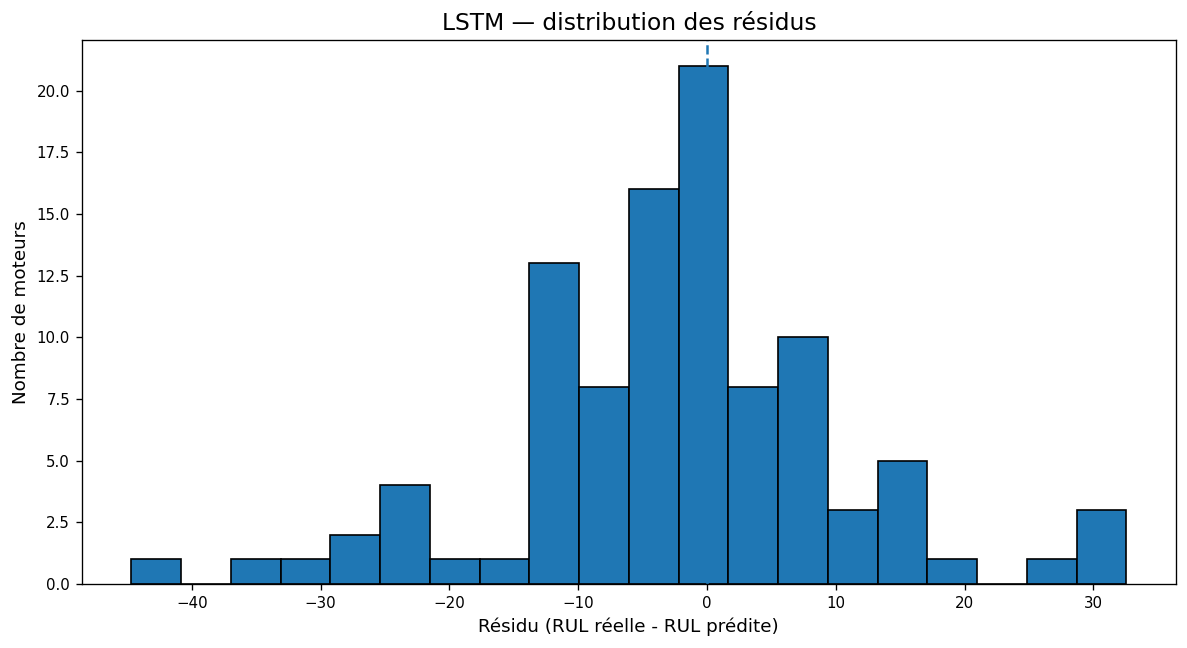

In [35]:
if prediction_df is not None and true_col and pred_col:
    residuals = prediction_df[true_col] - prediction_df[pred_col]
    plt.figure()
    plt.hist(residuals.dropna(), bins=20, edgecolor="black")
    plt.axvline(0, linestyle="--", linewidth=1.5)
    plt.title("LSTM — distribution des résidus")
    plt.xlabel("Résidu (RUL réelle - RUL prédite)")
    plt.ylabel("Nombre de moteurs")
    plt.tight_layout()
    plt.savefig(FIG_DIR/"lstm_residus.png", bbox_inches="tight")
    plt.show()


## 11. Importance des variables LightGBM

La figure est générée si un CSV d'importance LightGBM est présent dans `results/`.


In [ ]:
importance_df, importance_path = load_csv([
    "lightgbm_feature_importance.csv",
    "lightgbm_importance.csv"
])
print("Importance :", importance_path)

if importance_df is not None:
    fcol = next((c for c in ["feature","Feature","features","variable"]
                 if c in importance_df.columns), None)
    vcol = next((c for c in ["importance","Importance","gain","split"]
                 if c in importance_df.columns), None)

    if fcol and vcol:
        top = (importance_df[[fcol,vcol]]
               .sort_values(vcol, ascending=False)
               .head(15)
               .sort_values(vcol))
        plt.figure(figsize=(9,6))
        plt.barh(top[fcol], top[vcol])
        plt.title("LightGBM — 15 variables les plus importantes")
        plt.xlabel("Importance")
        plt.ylabel("Variable")
        plt.tight_layout()
        plt.savefig(FIG_DIR/"lightgbm_feature_importance.png", bbox_inches="tight")
        plt.show()
    else:
        print("Colonnes d'importance non identifiées.")


# Figures prioritaires pour le rapport

**Chapitre 3 — EDA**
- `eda_capteurs_constants.png`
- `eda_distribution_duree_vie.png`
- `eda_trajectoire_sensor_*.png`
- `eda_correlation_capteurs.png`
- `eda_distribution_rul.png`

**Chapitre 5 — Modélisation**
- `resultats_mae_rmse.png`
- `resultats_phm08.png`
- `groupkfold_mae_rmse.png`
- `lstm_reel_vs_predit.png` si disponible
- `lstm_residus.png` si disponible
- `lightgbm_feature_importance.png` si disponible

Toutes les figures sont enregistrées dans `figures_rapport/`.
